# Chamley–Judd の「資本課税ゼロが望ましい」という議論を否定する
## ―― 楔(くさび)の帳簿の付け方と、ラムゼイ・モデルへの回帰

* 文責: JRF (Author)
* 協力: Claude Opus 5.5 (Anthropic) ―― 定式化・Lean による証明・シミュレーション・文献整理を大きく補った。
* 版: 0.1.0 (2026-10-13)

このノートブックは、Python による数値計算と、Lean 4 + Mathlib による定理の形式証明を含む。
本文中の「§1」〜「§4」は Lean ファイル `CJ_formula.lean` の節を指す(ノートブックの節は「第 n 節」「6.2 節」のように書く)。
Lean のソースは各所の `%%writefile` セルで `CJ_formula.lean` に書き出し、**最後にまとめて検証**する
(Google Colab でも、ローカルでも動くようにしてある)。

## 要旨

蓮見 亮『動学マクロ経済学へのいざない』(2020) 第3章は、税のあるラムゼイ・モデルを使って
「税収が足りないなら、資本所得税より消費税を上げる方が望ましい」と結論する。
これは Chamley (1986)・Judd (1985) の「長期的には資本所得税はゼロが最適」という命題の、教科書的な簡易版である。

本稿の主張は次のとおり。

1. **(再現)** 蓮見モデルでは、一定の消費税は定常状態に一切影響しない(労働供給が非弾力的なので、事実上の一括税になる)。
   一方、資本課税は定常資本 $K^{\ast}$ と定常消費 $C^{\ast}$ を厳密に下げる。家計のオイラー方程式とラムゼイ計画者の修正黄金律を並べれば、
   $\tau_k = 0$ が出る。予算制約 (3.2) からオイラー方程式 (3.12) を導く部分も含め、これらを Lean で証明する(§1–§2)。
   なお、一括税 $\tau_{h,t}$ はこの導出で消える。
2. **(JRF の変形)** 二つの変形を入れる。
   (1) 消費税が資本の実効的な生産性・収益を変えること:$A \mapsto A/(1+\tau_c)^b$($b$ の符号は二通りに読める)。
   (2) 公共投資 $\gamma r K$ が資本の持ち主に比例して戻ること。
   すると、ラムゼイ配分を再現する資本税率は
   $$\tau_k^\dagger = 1 + \gamma - (1+\tau_c)^b$$
   となる。**資本税率は消費税率と公共投資に「からめて」決まり、$b \ne 0$ なら一般にゼロではない。**
   * $b<0$(JRF 2025 の説明:消費税による物価上昇が蓄積資本の価値を上げる)では、$\gamma = 0$ でも $\tau_k^\dagger>0$ になる。
     しかも $\tau_k^\dagger$ は $\tau_c$ とともに増える。「消費税を上げるなら資本課税も上げるべき」である。
   * $b>0$(2022 年の gist の実装:消費税が資本財にも掛かる)で $\gamma = \tau_k$ なら、結論が逆転する。
     消費税は上げない方がよく、資本税は(税収を公共投資で戻す限り)掛けても無害になる。
     ただし、そのときの資本税収は公共投資に回るので、政府消費 $g$ の財源にはならない。
   いずれも §3 で Lean により証明する。
3. **(ラムゼイへの回帰)** 予算制約 (3.2) に政府支出 $g_t$ を足し戻すと、税率が恒等的に消えて、
   ラムゼイ・モデル (2.28) にそのまま戻る(§4、Lean で証明)。
   Chamley–Judd の長期の目標配分とは、まさにこのラムゼイ・モデルの修正黄金律である。
4. **(結論)** 「どの税が楔を生むか」は、モデルの中で税と還元を**どう帳簿に付けるか**で決まる。
   その付け方を真の世界(ラムゼイ・モデル)が一意に決めることはない。
   JRF の変形が恣意的だとすれば、Chamley–Judd 型の財政モデルも同じ程度に恣意的である。
   したがって「資本課税ゼロ」はモデルの頑健な帰結とは言えない。

数値面でも、生涯厚生を基準にして税収中立な最適税率の組合せを求めると、
蓮見モデル ($b=0$) では $\tau_k^{\ast} \approx 0$(Chamley–Judd の再現)、
$b>0$ では $\tau_k^{\ast} \approx b > 0$ となった(第 6 節)。

なお、Gemini との過去の対話(2025)の結論の一つ「$b=0$ で $\gamma$ だけを入れても、消費税の引き上げは厚生を悪化させる」は、蓮見モデルの枠内では成り立たない。
$b=0,\ \gamma=\tau_k$ では両税とも定常状態に中立になる(`jrf2_only_neutral`)。
「言えなくなると思っていた」という JRF の当初の直観の方が正しかった。

## 1. 背景・過去の議論・参考文献

### この議論の出発点(JRF の過去の議論)

* JRF「資本家に有利すぎる財政モデルを批判する。蓮見 亮『動学マクロ経済学へのいざない』...」『JRF のひとこと』2022-06-02.
  http://jrf.cocolog-nifty.com/statuses/2022/06/post-3e0e5b.html
  ―― 本稿で扱う批判 (1)(2) と「$g_t$ を足すとラムゼイ・モデル (2.28) に戻る」という指摘の原文。
* JRF「蓮見 亮『動学マクロ経済学へのいざない』第3章「財政モデル: 税制と経済成長」の検算と批判」(dynamic_macro_economics_03.ipynb), GitHub Gist, 2022.
  https://gist.github.com/JRF-2018/e59fff66621f93f4e5f832aef9922720
  ―― 本の R ソースを Python で検算し、(1)(2) を入れた定常状態を数値で見たもの。
  そこでは「$b=1$ とすると、$\tau_c$ と $\tau_k$ のどちらを上げるのがよいかは $C$ と $K$ のどちらを重視するかで変わり、どちらがいいとは言えない」となっていた。
  本稿は、この判断基準を生涯厚生にそろえ、税収を中立にして、決着を付け直す試みでもある。
* JRF「資本課税についての議論 with Gemini 2.5 Flash」2025-05-19. 共有リンク https://gemini.google.com/share/79de6ebd30fb
  共有ページは AI からは読めないことがあるため、ログを Markdown で公開している:
  https://github.com/JRF-2018/misc_ipynb/blob/master/gemini_conversation-20250519.md 。主な内容は次のとおり。
  * Chamley–Judd の連続時間版の説明。家計 $(1-\tau_k)r^{\ast} = \rho$ (\*\*) と計画者 $r^{\ast}=\rho$ (\*\*\*) から $\tau_k^{\ast}=0$ を出す。
  * JRF の問題意識。AI は資本なので、資本蓄積を最優先すると「AI だけが成長し、人間はいらない・少子化でよい」となりかねない。
    一定の消費、つまり人間の生きる余地を守るには、資本課税も一定程度必要ではないか。Kaldor の支出税論にも触れている。
  * JRF による (1) の再説明。消費税の分だけ賃金を上げる必要があり、物価は消費税分以上に上がる。
    すると、蓄積済みの資本の価値が上がり、価格で見て、より少ない資本で生産できる。
  * Gemini による改造 Chamley–Judd の導出。$(1-\tau_k)\,r^{\ast}(1+\tau_c)^b = \rho$ から $\tau_k^{\ast} = 1 - 1/(1+\tau_c)^b$ を出し、
    $\gamma$ を入れて $\tau_k^{\ast} = 1 + \gamma - 1/(1+\tau_c)^b$ を得ている。
    $b = 0$ では $\tau_k^{\ast} = \gamma$ となる。
  
  本稿 §3 の楔定理は、$b$ の符号を問わない形でこれらを含む。Gemini の式は本稿の $b$ を $-b$ に置き換えたものに当たる。
  一方、Gemini の最後の回答「$b=0$ でも消費税の引き上げは厚生を悪化させる」は、労働供給の歪みを暗に仮定しており、蓮見モデルでは成り立たない(要旨の注を参照)。

### 原典・関連文献

(書誌は Claude の知識にもとづく。Guerreiro–Rebelo–Teles (2022) と Costinot–Werning (2023) はウェブ検索で書誌を確認済み。その他は原典での確認を推奨する。)

* 蓮見 亮 (2020)『動学マクロ経済学へのいざない』日本評論社。特に第3章「財政モデル: 税制と経済成長」。
  サポートページ https://www.rhasumi.net/wiki/wiki.cgi?page=dynamicmodels ,
  ソース https://github.com/rhasumi/dynamicmodels/blob/master/ch3/Ramsey_tax.R
* Ljungqvist, L. and T. J. Sargent (2018) *Recursive Macroeconomic Theory*, 4th ed., MIT Press. Chapter 11 "Fiscal Policies in a Growth Model". ―― 蓮見 (2020) 第3章のモデルが参考にした章。
* Chamley, C. (1986) "Optimal Taxation of Capital Income in General Equilibrium with Infinite Lives," *Econometrica* 54(3), 607–622.
* Judd, K. L. (1985) "Redistributive Taxation in a Simple Perfect Foresight Model," *Journal of Public Economics* 28(1), 59–83.
* Atkinson, A. B. and J. E. Stiglitz (1976) "The Design of Tax Structure: Direct versus Indirect Taxation," *Journal of Public Economics* 6, 55–75.
* Diamond, P. and J. Mirrlees (1971) "Optimal Taxation and Public Production I: Production Efficiency," *American Economic Review* 61(1), 8–27.
* Barro, R. J. (1990) "Government Spending in a Simple Model of Endogenous Growth," *Journal of Political Economy* 98(5), S103–S125.
  ―― 生産的な政府支出があると、最適な所得(資本)課税率は正になる。JRF の (2) と同じ方向の古典。
* Correia, I. H. (1996) "Should Capital Income Be Taxed in the Steady State?" *Journal of Public Economics* 60(1), 147–151.
  ―― 課税できない生産要素があると、定常状態の資本課税はゼロでなくなる。
* Aiyagari, S. R. (1995) "Optimal Capital Income Taxation with Incomplete Markets, Borrowing Constraints, and Constant Discounting," *Journal of Political Economy* 103(6), 1158–1175.
* Lansing, K. J. (1999) "Optimal Redistributive Capital Taxation in a Neoclassical Growth Model," *Journal of Public Economics* 73(3), 423–453.
* Chari, V. V. and P. J. Kehoe (1999) "Optimal Fiscal and Monetary Policy," in *Handbook of Macroeconomics* Vol. 1C, ch. 26.
* Conesa, J. C., S. Kitao and D. Krueger (2009) "Taxing Capital? Not a Bad Idea After All!" *American Economic Review* 99(1), 25–48.
* Straub, L. and I. Werning (2020) "Positive Long-Run Capital Taxation: Chamley–Judd Revisited," *American Economic Review* 110(1), 86–119.
  ―― Chamley–Judd モデルの内部でも、長期の資本課税がゼロに収束しない場合があることを示した。
* Chari, V. V., J. P. Nicolini and P. Teles (2020) "Optimal Capital Taxation Revisited," *Journal of Monetary Economics* 116, 147–165.
* Guerreiro, J., S. Rebelo and P. Teles (2022) "Should Robots Be Taxed?" *Review of Economic Studies* 89(1), 279–311. doi:10.1093/restud/rdab019
  ―― 定型業務の労働者が労働市場に残っているあいだは、ロボットへの課税が最適になる。
* Costinot, A. and I. Werning (2023) "Robots, Trade, and Luddism: A Sufficient Statistic Approach to Optimal Technology Regulation," *Review of Economic Studies* 90(5), 2261–2291. doi:10.1093/restud/rdac076
  ―― 分配への配慮から、ロボットや貿易へのゼロでない課税が正当化される(ただし規模は小さい)。
* Auerbach, A. J. and L. J. Kotlikoff (1987) *Dynamic Fiscal Policy*, Cambridge University Press.
  ―― 消費税への移行は既存資本への一回限りの課税を含む。消費税は資本に中立とは限らない。
* Saez, E. and S. Stantcheva (2018) "A Simpler Theory of Optimal Capital Taxation," *Journal of Public Economics* 162, 120–142.

本稿の新しさは、文献の結論を足し合わせることにはない。
**蓮見モデルという一つの小さな枠組みの中で、帳簿の付け方を変えるだけで結論が $\tau_k=0$ から逆転まで動くこと**を、
Lean で厳密に示す点にある。

念のため付け加えておく。Chamley–Judd への批判が「資本家の陰謀」で封殺されてきた、ということはない。
上に挙げたとおり、Straub–Werning (2020) や Conesa–Kitao–Krueger (2009) をはじめ、
正の資本課税を導く研究は経済学の主流の学術誌で繰り返し発表されてきた。
ただし非対称性はあった。「資本課税ゼロ」は結論がきれいで意外性もあるため、教科書や政策論議ではそれだけが「定理」として流通しやすい。
批判の側は、異質な家計・不完備市場・効用の形状といった仮定の追加や数値計算に頼ることが多く、広まりにくかった。
日本の財政論議で消費税の増税が支持されてきた文脈では、この傾向がさらに強かったかもしれない。
これは封殺ではなく、単純な結論ほど伝わりやすいという選択バイアスと見るのが妥当だろう。

そのうえで、**今回のような簡単な数理モデルでも批判ができる**ことは、あまり知られていなかったと思われる。
教科書と同じ代表的家計・労働固定・対数効用の枠組みのままで、
予算制約 (3.2) の帳簿の付け方を少し変えるだけで結論が動き、$g_t$ を足し戻せばラムゼイ・モデルに戻る。
本稿が示したいのは、この点である。

## 2. 蓮見モデル(第3章)の再構成

本書第3章(pp.53–61)と R ソース `Ramsey_tax.R` にもとづき、モデルを次のようにまとめる。式番号は本書のものである。
なお、本書の補遺によれば、このモデルは Ljungqvist and Sargent (2018) の 11 章を参考にしている。

**家計**:生涯効用 $U_t = \sum_{i=0}^{\infty} \beta^i \ln C_{t+i}$ (3.1) を最大化する。予算制約は
$$
K_{t+1} + (1+\tau_{c,t})\, C_t + \tau_{h,t} = (1-\tau_{k,t})\, r_t K_t + w_t + (1-\delta) K_t \tag{3.2}
$$
である。$\tau_{h,t}$ は一括税である。

**企業**:$Y_t = A_t K_t^{\alpha}$(労働は 1 に固定)(3.9)。競争的要素価格は $r_t = \alpha A_t K_t^{\alpha-1}$ (3.10), $w_t = (1-\alpha) A_t K_t^{\alpha}$ (3.11)。

**政府**:政府支出 $g_t$ と同額を税で集める。
$$
g_t = \tau_{c,t} C_t + \tau_{k,t} r_t K_t + \tau_{h,t} \tag{3.13}
$$
消費税と資本所得税で足りない分は一括税 $\tau_{h,t}$ で集め、余れば一括交付金として返す。
本書は、一括税を「政府が無利子で公債を発行して資金調達している」と解釈した方が実際に近い、と述べている。

**資本の遷移式**((3.2) と (3.13) から従う。§4 で Lean により確認する):
$$
K_{t+1} = A_t K_t^{\alpha} + (1-\delta) K_t - C_t - g_t . \tag{3.15}
$$
**オイラー方程式**(ラグランジアン (3.3) の一階条件 (3.4)(3.5) から $\lambda_t$ を消去したもの。R ソースの残差関数そのもの):
$$
\frac{(1+\tau_{c,t+1})\,C_{t+1}}{(1+\tau_{c,t})\,C_t} = \beta\left[(1-\tau_{k,t+1})\,\alpha A_{t+1} K_{t+1}^{\alpha-1} - \delta + 1\right]. \tag{3.12}
$$
一括税 $\tau_{h,t}$ はオイラー方程式から消える。本書も「一括税 $\tau_{h,t}$ は残差として決まるので、モデルを解く際には必ずしも考慮する必要はない」としている。

**定常状態**:$\rho := 1/\beta - 1 + \delta$ とおくと、
$$
K^{\ast} = \left(\frac{\rho}{(1-\tau_k)\,\alpha A}\right)^{\frac{1}{\alpha-1}} \tag{3.18}
$$
$$
C^{\ast} = A K^{\ast \alpha} - g - \delta K^{\ast} \tag{3.19}
$$
$K^{\ast}$ に $\tau_c$ は現れない。一定の消費税は、オイラー方程式の分子と分母で打ち消し合う。

**ラムゼイ・モデル (2.28)**(政府なし):
$$
K_{t+1} = A K_t^{\alpha} + (1-\delta)K_t - C_t, \qquad \frac{C_{t+1}}{C_t} = \beta\left[\alpha A K_{t+1}^{\alpha-1} + 1 - \delta\right].
$$
その定常状態は**修正黄金律** $\alpha A K^{\alpha-1} = \rho$ である。

## 3. Chamley–Judd の元の議論と、蓮見モデルでの「資本課税ゼロ」

### 3.1 Chamley–Judd の論理(主双対アプローチ)

Chamley (1986) では、政府はコミットメントのもとで歪みのある税だけを使い、外生的な支出を賄う。
最適課税(ラムゼイ問題)は、家計の最適化条件を「実行可能性制約」として組み込み、配分 $\{C_t, K_{t+1}\}$ を直接選ぶ問題に書き換えられる。
その一階条件の資本に関する部分は、$W$ を「効用 + 実行可能性制約の乗数項」として
$$
W_C(t) = \beta\, W_C(t+1)\,\bigl(F_K(K_{t+1}) + 1 - \delta\bigr)
$$
となる。配分が定常状態に収束すれば $W_C$ は一定なので、**計画者の長期条件は修正黄金律**
$$
\beta\,(F_K + 1 - \delta) = 1
$$
になる。一方、家計の定常オイラー方程式は(蓮見型の粗収益課税で)
$$
\beta\,\bigl((1-\tau_k) F_K + 1 - \delta\bigr) = 1 .
$$
両者が同時に成り立ち $F_K \ne 0$ なら $\tau_k = 0$ である。
これが Chamley–Judd の命題の核心で、Lean では `cj_core` として証明する。

ここで強調しておきたいのは、**計画者の長期目標が、税も政府もないラムゼイ・モデル (2.28) の定常状態そのもの**だという点である。
Chamley–Judd の結論は「長期的には、家計の私的収益率と社会的収益率のあいだの楔を消せ」と言い換えられる。
ゼロでなければならないのは「楔」であって、「資本税率」がゼロであることはその帰結にすぎない。

### 3.2 蓮見モデルでの再現

蓮見モデルは最適課税問題を解いてはいない。定常状態の比較静学とシミュレーションで同じ結論を示している。

* 一定の $\tau_c$ は $K^{\ast}, C^{\ast}$ に影響しない(`steady_euler_iff`, `hasumi_consumption_tax_neutral`)。
* $0<\tau_k<1$ は $K^{\ast}$ と $C^{\ast}$ を厳密に下げる(`hasumi_capital_tax_harmful`)。

証明の鍵は、0<α<1 に対する Bernoulli 型不等式 $(1+s)^\alpha < 1 + \alpha s$ から得られる接線評価である(`net_output_strictMono`)。
これにより、黄金律より手前($F_K > \delta$)では $K$ が多いほど $AK^\alpha - \delta K$ が大きいことが言える。

**Claude による補足(重要)**:

* 労働供給が固定のこのモデルでは、**一定の消費税は事実上の一括税**である。
  したがって「消費税の方が良い」という結論は、「一括税の方が歪みのある税より良い」という自明な命題を言い換えたものにすぎない。
  本書自身もこの点を認めている。脚注 2 (p.59) は「労働供給が外生であることが、消費税率が定常状態に影響を与えないことの理由の 1 つである」と述べる。
  p.60 では「税は全て一括税 $\tau_{h,t}$ により徴収すればよいように思われるが、これは現実性に乏しい」と述べたうえで、p.61 の結論に進んでいる。
  労働供給が内生なら、消費税は労働所得税と同様に労働・余暇の選択を歪める(Atkinson–Stiglitz 的な議論)。
  その場合、比較はずっと微妙になる。
* 定常消費 $C^{\ast}$ だけを基準にすると、$K^{\ast}$ を黄金律 $F_K = \delta$ まで増やす**資本補助金**($\tau_k<0$)が最善になってしまう。
  修正黄金律は黄金律より手前にあるからである。
  Chamley–Judd の $\tau_k = 0$ は、移行過程を含む**生涯厚生**を基準にしてはじめて出てくる。
  そのため本稿の数値実験(第 6 節)では生涯厚生 $\sum \beta^t \log C_t$ を基準にする。

### Lean: 準備と §1–§2

まず、Lean ファイルの冒頭(パラメータ $\alpha,\beta,\delta$ と基本的な定義)を書き出す。

In [1]:
%%writefile CJ_formula.lean
import Mathlib

/-!
# Chamley–Judd の「資本課税ゼロ」を Lean で検討する

蓮見 亮『動学マクロ経済学へのいざない』(2020) 第3章の「税のあるラムゼイ・モデル」を
主に定常状態に絞って定式化し、

* §1 Chamley–Judd の核心(家計のオイラー方程式と修正黄金律が両立 ⇒ τk = 0)
* §2 蓮見モデル: 予算制約 (3.2) からオイラー方程式 (3.12) を変分で導く。
  消費税は定常状態に中立、資本課税は K*, C* を厳密に下げる
* §3 JRF の変形 (1) 消費税による実効生産性の変化 A/(1+τc)^b (b の符号は問わない),
  (2) 公共投資 γ r K
* §4 予算制約に g を足し戻すとラムゼイ・モデル (2.28) に戻ること

を示す。
-/

namespace CJ

open Real Filter Topology

/-- モデルのパラメータ。生産関数は Y = A K^α, 効用は対数(オイラー方程式が比になる)。 -/
structure Params where
  α : ℝ
  β : ℝ
  δ : ℝ
  hα0 : 0 < α
  hα1 : α < 1
  hβ0 : 0 < β
  hβ1 : β < 1
  hδ0 : 0 < δ

variable (p : Params)

namespace Params

/-- 必要粗収益率 ρ = 1/β - 1 + δ (修正黄金律で資本の限界生産力が等しくなる値) -/
noncomputable def ρ : ℝ := 1 / p.β - 1 + p.δ

lemma δ_lt_ρ : p.δ < p.ρ := by
  have : 1 < 1 / p.β := by rw [lt_div_iff₀ p.hβ0]; linarith [p.hβ1]
  unfold ρ; linarith

lemma ρ_pos : 0 < p.ρ := lt_trans p.hδ0 p.δ_lt_ρ

/-- 資本の限界生産力 r = α A K^(α-1) -/
noncomputable def mpk (A K : ℝ) : ℝ := p.α * A * K ^ (p.α - 1)

/-- 定常状態の消費(資源制約 K = A K^α + (1-δ)K - C - g より) C = A K^α - δ K - g -/
noncomputable def css (A K g : ℝ) : ℝ := A * K ^ p.α - p.δ * K - g

Writing CJ_formula.lean


§1: Chamley–Judd の核心。家計の定常オイラー方程式と修正黄金律が両立するなら $\tau_k = 0$。

In [2]:
%%writefile -a CJ_formula.lean
/-! ## §1 Chamley–Judd の核心 -/

/-- 家計の定常オイラー方程式 β((1-τk) r + 1 - δ) = 1 (蓮見型: 粗収益に課税) と、
ラムゼイ計画者の長期条件(修正黄金律) β(r + 1 - δ) = 1 が同時に成り立つなら τk = 0。 -/
theorem cj_core {τk r : ℝ} (hr : r ≠ 0)
    (hHH : p.β * ((1 - τk) * r + 1 - p.δ) = 1)
    (hPL : p.β * (r + 1 - p.δ) = 1) : τk = 0 := by
  have h : (p.β * r) * τk = 0 := by linear_combination hPL - hHH
  rcases mul_eq_zero.mp h with h' | h'
  · exact absurd h' (mul_ne_zero p.hβ0.ne' hr)
  · exact h'

Appending to CJ_formula.lean


§2 (前半): オイラー方程式 (3.12) の残差を、本(と R ソース)どおりに定義する。

In [3]:
%%writefile -a CJ_formula.lean
/-! ## §2 蓮見モデル -/

/-- 蓮見(2020) 第3章のオイラー方程式の残差(対数効用)。
`(1+τc') C' / ((1+τc) C) - β((1-τk') α A K'^(α-1) - δ + 1)` -/
noncomputable def eulerResid (A τc τc' τk' C C' K' : ℝ) : ℝ :=
  (1 + τc') * C' / ((1 + τc) * C) - p.β * ((1 - τk') * p.mpk A K' - p.δ + 1)

Appending to CJ_formula.lean


§2 (オイラー方程式の導出): 予算制約 (3.2) から、変分によってオイラー方程式 (3.12) を導く。

本書はラグランジアン (3.3) から一階条件 (3.4) $1/C_t - (1+\tau_{c,t})\lambda_t = 0$ と
(3.5) $\beta[r_{t+1}(1-\tau_{k,t+1}) - \delta + 1]\lambda_{t+1} - \lambda_t = 0$ を出し、$\lambda$ を消去して (3.12) を得ている。
Lean では乗数を使わず、同じことを**一期間だけの変分**で示す。

$t$ 期の消費を $\varepsilon/(1+\tau_{c,t})$ 減らして $K_{t+1}$ を $\varepsilon$ 増やし、その収益 $\varepsilon R_{t+1}$, $R_{t+1} = (1-\tau_{k,t+1})r_{t+1} + 1 - \delta$ で
$t+1$ 期の消費を $\varepsilon R_{t+1}/(1+\tau_{c,t+1})$ 増やす。
この変分は、他の期を一切変えずに $t$ 期・$t+1$ 期の (3.2) を保つ(`perturbation_feasible`)。
最適計画ではこれで (3.1) を上げられないので、
$$
\varphi(\varepsilon) = \ln\!\Bigl(C_t - \tfrac{\varepsilon}{1+\tau_{c,t}}\Bigr) + \beta \ln\!\Bigl(C_{t+1} + \tfrac{\varepsilon R_{t+1}}{1+\tau_{c,t+1}}\Bigr)
$$
は $\varepsilon=0$ で極大になる(`isLocalMax_of_opt`)。その微分がゼロになることから (3.12) が出る(`foc_of_isLocalMax`, `euler_derivation`)。

定理の依存関係は次のとおりである。最後の `euler_from_budget` が「(3.2) からの導出」の本体になる。

* `euler_derivation`:変分後の効用 $\varphi(\varepsilon) \le \varphi(0)$ を仮定して、(3.12) を出す。これは純粋に微分の議論で、(3.2) は登場しない。
* `euler_from_budget`:仮定を (3.2) の言葉で書く。
  * 計画 $(C_t, K_{t+1}, C_{t+1})$ が $t$ 期・$t+1$ 期の (3.2)(`budget32 = 0`)を満たす。
  * $K_t, K_{t+2}$ と他の期を固定して (3.2) を満たすどんな計画 $(C_1, K_1, C_2)$ よりも、$\ln C_t + \beta\ln C_{t+1}$ が小さくない。
  
  このとき (3.12) が成り立つ。証明では `perturbation_feasible` により変分した計画が (3.2) を満たすことを示し、
  2 つ目の仮定を適用して `euler_derivation` に帰着させる。

**一括税 $\tau_{h,t}$ は変分に現れない**ので、仮定にも結論にも出てこない。ラグランジュ乗数法で $\tau_{h,t}$ が消えるのと同じ理由である。
同じ変分を税率ゼロの予算制約に行えば、ラムゼイ・モデルのオイラー方程式になる(`ramsey_euler_derivation`、§4)。

なお、無限期間の和 (3.1) そのものは形式化していない。
「(3.1) の最適計画なら、他の期を固定した二期間の付け替えで効用は上がらない」という部分は、仮定 `hopt` として置いている。
他の期の項は変わらないので、これは (3.1) の最適性からただちに従う。
$r_{t+1} = \alpha A K_{t+1}^{\alpha-1}$ は家計にとって所与の価格として扱う。家計が自分の $K_1$ を動かしても、市場の $r_{t+1}$ は変わらない。

In [4]:
%%writefile -a CJ_formula.lean
/-! ### 予算制約 (3.2) からオイラー方程式 (3.12) を導く

本の (3.2): `K_{t+1} + (1+τ_{c,t}) C_t + τ_{h,t} = (1-τ_{k,t}) r_t K_t + w_t + (1-δ) K_t`。
t 期の消費を ε/(1+τ_{c,t}) だけ減らして K_{t+1} を ε 増やし、その収益で t+1 期の消費を増やす
という「一期間だけの変分」は、他の期を変えずに (3.2) を保つ。最適計画ではこの変分で
生涯効用 (3.1) を上げられないので、ε = 0 での微分がゼロになり (3.12) が出る。
一括税 τ_h は変分に現れないので消える(ラグランジュ乗数法で消えるのと同じ理由)。
-/

/-- (3.2) の残差 (= 0 が予算制約)。r, w は家計にとって所与の価格。 -/
noncomputable def budget32 (τc τk τh r w K C K' : ℝ) : ℝ :=
  K' + (1 + τc) * C + τh - ((1 - τk) * r * K + w + (1 - p.δ) * K)

/-- 変分の実行可能性: t 期と t+1 期の (3.2) を満たす計画を、
C_t ↦ C_t - ε/(1+τc), K_{t+1} ↦ K_{t+1} + ε, C_{t+1} ↦ C_{t+1} + ε R/(1+τc')
(R = (1-τk') r' + 1 - δ) と動かしても、両期の (3.2) は保たれる(τh, τh' はそのまま)。 -/
theorem perturbation_feasible {τc τk τh r w K C K' τc' τk' τh' r' w' C' K'' : ℝ}
    (hc : 1 + τc ≠ 0) (hc' : 1 + τc' ≠ 0)
    (h1 : p.budget32 τc τk τh r w K C K' = 0) (h2 : p.budget32 τc' τk' τh' r' w' K' C' K'' = 0)
    (ε : ℝ) :
    p.budget32 τc τk τh r w K (C - ε / (1 + τc)) (K' + ε) = 0 ∧
    p.budget32 τc' τk' τh' r' w' (K' + ε)
      (C' + ε * ((1 - τk') * r' + 1 - p.δ) / (1 + τc')) K'' = 0 := by
  unfold budget32 at *
  constructor
  · field_simp; linear_combination h1
  · field_simp; linear_combination h2

/-- 一階条件: ε ↦ log(C - ε/q) + β log(C' + εR/q') が ε = 0 で極大なら q' C' / (q C) = β R。 -/
theorem foc_of_isLocalMax {bt q q' R C C' : ℝ} (hC : 0 < C) (hC' : 0 < C') (hq : 0 < q)
    (hq' : 0 < q')
    (hmax : IsLocalMax (fun ε : ℝ => Real.log (C - ε / q) + bt * Real.log (C' + ε * R / q')) 0) :
    q' * C' / (q * C) = bt * R := by
  have h1 : HasDerivAt (fun ε : ℝ => C - ε / q) (-(1 / q)) 0 := by
    simpa using ((hasDerivAt_id (0:ℝ)).div_const q).const_sub C
  have h2 : HasDerivAt (fun ε : ℝ => C' + ε * R / q') (R / q') 0 := by
    simpa using (((hasDerivAt_id (0:ℝ)).mul_const R).div_const q').const_add C'
  have h1l := h1.log (by simp; exact hC.ne')
  have h2l := h2.log (by simp; exact hC'.ne')
  have h0 := hmax.hasDerivAt_eq_zero (h1l.add (h2l.const_mul bt))
  simp at h0
  field_simp at h0 ⊢
  linarith

/-- 「どの実行可能な変分でも効用が上がらない」なら ε = 0 は極大点。 -/
theorem isLocalMax_of_opt {bt q q' R C C' : ℝ} (hC : 0 < C) (hC' : 0 < C')
    (hopt : ∀ ε : ℝ, 0 < C - ε / q → 0 < C' + ε * R / q' →
      Real.log (C - ε / q) + bt * Real.log (C' + ε * R / q') ≤ Real.log C + bt * Real.log C') :
    IsLocalMax (fun ε : ℝ => Real.log (C - ε / q) + bt * Real.log (C' + ε * R / q')) 0 := by
  have c1 : ContinuousAt (fun ε : ℝ => C - ε / q) 0 := by fun_prop
  have c2 : ContinuousAt (fun ε : ℝ => C' + ε * R / q') 0 := by fun_prop
  have e1 : ∀ᶠ ε in 𝓝 (0:ℝ), 0 < C - ε / q :=
    c1.eventually (lt_mem_nhds (by simpa using hC))
  have e2 : ∀ᶠ ε in 𝓝 (0:ℝ), 0 < C' + ε * R / q' :=
    c2.eventually (lt_mem_nhds (by simpa using hC'))
  filter_upwards [e1, e2] with ε h1 h2
  simpa using hopt ε h1 h2

/-- **オイラー方程式 (3.12) の導出**: (3.2) のもとで、t 期と t+1 期のあいだの
実行可能な変分(`perturbation_feasible`)によって生涯効用 (3.1) の
β^t ln C_t + β^{t+1} ln C_{t+1} の部分を上げられないなら、r' = α A K'^(α-1) のもとで
オイラー方程式 (3.12) が成り立つ。一括税 τh は仮定にも結論にも現れない。 -/
theorem euler_derivation {A τc τc' τk' C C' K' : ℝ} (hC : 0 < C) (hC' : 0 < C')
    (hc : 0 < 1 + τc) (hc' : 0 < 1 + τc')
    (hopt : ∀ ε : ℝ, 0 < C - ε / (1 + τc) →
      0 < C' + ε * ((1 - τk') * p.mpk A K' + 1 - p.δ) / (1 + τc') →
      Real.log (C - ε / (1 + τc))
        + p.β * Real.log (C' + ε * ((1 - τk') * p.mpk A K' + 1 - p.δ) / (1 + τc'))
        ≤ Real.log C + p.β * Real.log C') :
    p.eulerResid A τc τc' τk' C C' K' = 0 := by
  have h := foc_of_isLocalMax hC hC' hc hc' (isLocalMax_of_opt hC hC' hopt)
  unfold eulerResid
  rw [h]; ring

/-- **(3.2) からのオイラー方程式 (3.12) の導出**。
計画 (C, K', C') が t 期・t+1 期の (3.2) を満たし(h1, h2)、K_t と K_{t+2} = K'' および他の期を
固定したまま (3.2) を満たす任意の計画 (C₁, K₁, C₂) よりも β^t ln C_t + β^{t+1} ln C_{t+1} が
小さくない(hopt: 生涯効用 (3.1) の最適性から従う)とする。r' = α A K'^(α-1) は家計にとって
所与の価格(家計が K₁ を変えても r' は変わらない)。このときオイラー方程式 (3.12) が成り立つ。
証明は `perturbation_feasible` で変分が (3.2) を保つことを示し、`euler_derivation` に帰着させる。 -/
theorem euler_from_budget {A τc τk τh r w K C K' τc' τk' τh' w' C' K'' : ℝ}
    (hC : 0 < C) (hC' : 0 < C') (hc : 0 < 1 + τc) (hc' : 0 < 1 + τc')
    (h1 : p.budget32 τc τk τh r w K C K' = 0)
    (h2 : p.budget32 τc' τk' τh' (p.mpk A K') w' K' C' K'' = 0)
    (hopt : ∀ C₁ K₁ C₂ : ℝ, 0 < C₁ → 0 < C₂ →
      p.budget32 τc τk τh r w K C₁ K₁ = 0 →
      p.budget32 τc' τk' τh' (p.mpk A K') w' K₁ C₂ K'' = 0 →
      Real.log C₁ + p.β * Real.log C₂ ≤ Real.log C + p.β * Real.log C') :
    p.eulerResid A τc τc' τk' C C' K' = 0 := by
  apply p.euler_derivation hC hC' hc hc'
  intro ε hε1 hε2
  obtain ⟨f1, f2⟩ := p.perturbation_feasible hc.ne' hc'.ne' h1 h2 ε
  exact hopt _ _ _ hε1 hε2 f1 f2

Appending to CJ_formula.lean


§2 (定常状態): 定常状態では $\tau_c$ が消えることを示す。

In [5]:
%%writefile -a CJ_formula.lean
/-- 定常状態(税率も一定)ではオイラー方程式は τc を含まない条件 (1-τk) r = ρ に帰着する。
すなわち一定の消費税は定常状態に対して中立。 -/
theorem steady_euler_iff {A τc τk C K : ℝ} (hC : 0 < C) (hc : 0 < 1 + τc) :
    p.eulerResid A τc τc τk C C K = 0 ↔ (1 - τk) * p.mpk A K = p.ρ := by
  have hne : (1 + τc) * C ≠ 0 := by positivity
  have hβ := p.hβ0.ne'
  unfold eulerResid ρ
  rw [div_self hne]
  constructor
  · intro h
    field_simp
    linarith
  · intro h
    rw [h]
    field_simp
    ring

/-- 消費税中立性: 定常状態の条件は τc をいくら変えても同じ。 -/
theorem hasumi_consumption_tax_neutral {A τc τc' τk C K : ℝ} (hC : 0 < C)
    (hc : 0 < 1 + τc) (hc' : 0 < 1 + τc') :
    p.eulerResid A τc τc τk C C K = 0 ↔ p.eulerResid A τc' τc' τk C C K = 0 := by
  rw [p.steady_euler_iff hC hc, p.steady_euler_iff hC hc']

Appending to CJ_formula.lean


§2 (中盤): 定常資本 $K^{\ast}(B) = (\rho/(\alpha B))^{1/(\alpha-1)}$ を定義し、存在・一意性・単調性を示す。
$B$ は「有効な収益係数」で、楔 $W$ と(実効)生産性 $A$ の積 $B = W A$ である。

In [6]:
%%writefile -a CJ_formula.lean
/-- 定常資本: α B K^(α-1) = ρ の解。B は「有効な収益係数」(楔 × 生産性)。 -/
noncomputable def kStar (B : ℝ) : ℝ := (p.ρ / (p.α * B)) ^ (1 / (p.α - 1))

lemma αm1_neg : p.α - 1 < 0 := by linarith [p.hα1]

lemma kStar_pos {B : ℝ} (hB : 0 < B) : 0 < p.kStar B := by
  have := p.ρ_pos; have := p.hα0
  unfold kStar; positivity

lemma kStar_spec {B : ℝ} (hB : 0 < B) :
    p.α * B * p.kStar B ^ (p.α - 1) = p.ρ := by
  have := p.ρ_pos; have := p.hα0
  have hx : 0 ≤ p.ρ / (p.α * B) := by positivity
  have hy : p.α - 1 ≠ 0 := p.αm1_neg.ne
  unfold kStar
  rw [one_div, Real.rpow_inv_rpow hx hy]
  field_simp

lemma kStar_rpow {B : ℝ} (hB : 0 < B) :
    p.kStar B ^ (p.α - 1) = p.ρ / (p.α * B) := by
  have := p.hα0
  rw [← p.kStar_spec hB]
  field_simp

/-- 定常資本の一意性 -/
lemma steady_unique {B K : ℝ} (hB : 0 < B) (hK : 0 < K)
    (h : p.α * B * K ^ (p.α - 1) = p.ρ) : K = p.kStar B := by
  have := p.hα0
  have h1 : K ^ (p.α - 1) = p.kStar B ^ (p.α - 1) := by
    rw [p.kStar_rpow hB, ← h]; field_simp
  exact (Real.rpow_left_inj hK.le (p.kStar_pos hB).le p.αm1_neg.ne).mp h1

/-- 有効な収益係数が大きいほど定常資本は大きい -/
lemma kStar_strictMono {B₁ B₂ : ℝ} (h1 : 0 < B₁) (h12 : B₁ < B₂) :
    p.kStar B₁ < p.kStar B₂ := by
  have h2 : 0 < B₂ := lt_trans h1 h12
  have := p.ρ_pos; have := p.hα0
  have hlt : p.kStar B₂ ^ (p.α - 1) < p.kStar B₁ ^ (p.α - 1) := by
    rw [p.kStar_rpow h1, p.kStar_rpow h2]
    apply div_lt_div_of_pos_left p.ρ_pos (by positivity)
    exact mul_lt_mul_of_pos_left h12 p.hα0
  exact (Real.rpow_lt_rpow_iff_of_neg (p.kStar_pos h2) (p.kStar_pos h1) p.αm1_neg).mp hlt

lemma kStar_injective {B₁ B₂ : ℝ} (h1 : 0 < B₁) (h2 : 0 < B₂)
    (h : p.kStar B₁ = p.kStar B₂) : B₁ = B₂ := by
  rcases lt_trichotomy B₁ B₂ with hl | he | hg
  · exact absurd h (p.kStar_strictMono h1 hl).ne
  · exact he
  · exact absurd h (p.kStar_strictMono h2 hg).ne'

/-- 定常資本での限界生産力: α A K*^(α-1) = ρ / W  (B = W A のとき) -/
lemma mpk_kStar {W A : ℝ} (hW : 0 < W) (hA : 0 < A) :
    p.mpk A (p.kStar (W * A)) = p.ρ / W := by
  have h := p.kStar_spec (mul_pos hW hA)
  unfold mpk
  rw [eq_div_iff hW.ne', ← h]; ring

Appending to CJ_formula.lean


§2 (後半): 鍵となる補題(Bernoulli 型不等式による接線評価)と、蓮見モデルの結論「資本課税は $K^{\ast}, C^{\ast}$ を厳密に下げる」。

In [7]:
%%writefile -a CJ_formula.lean
/-- **鍵となる補題**(黄金律の手前では資本が多いほど純産出が多い)。
K₁ < K₂ かつ K₂ での限界生産力が δ を超えれば A K₁^α - δK₁ < A K₂^α - δK₂。
証明は Bernoulli 型不等式 (1+s)^α < 1 + α s (0<α<1) による接線評価。 -/
lemma net_output_strictMono {A K₁ K₂ : ℝ} (hA : 0 < A) (hK1 : 0 < K₁) (h12 : K₁ < K₂)
    (hgr : p.δ < p.mpk A K₂) :
    A * K₁ ^ p.α - p.δ * K₁ < A * K₂ ^ p.α - p.δ * K₂ := by
  have hK2 : 0 < K₂ := lt_trans hK1 h12
  set s := K₁ / K₂ - 1 with hs
  have hs1 : -1 ≤ s := by rw [hs]; have : 0 < K₁ / K₂ := by positivity
                          linarith
  have hs0 : s ≠ 0 := by
    rw [hs]; intro h
    have : K₁ / K₂ = 1 := by linarith
    rw [div_eq_one_iff_eq hK2.ne'] at this; linarith
  have hb := _root_.rpow_one_add_lt_one_add_mul_self hs1 hs0 p.hα0 p.hα1
  have e1 : (1 + s) = K₁ / K₂ := by rw [hs]; ring
  rw [e1, Real.div_rpow hK1.le hK2.le] at hb
  have hK2a : 0 < K₂ ^ p.α := Real.rpow_pos_of_pos hK2 _
  -- K₁^α < K₂^α (1 + α (K₁/K₂ - 1)) = K₂^α + α K₂^(α-1) (K₁ - K₂)
  have hb2 : K₁ ^ p.α < K₂ ^ p.α + p.α * K₂ ^ (p.α - 1) * (K₁ - K₂) := by
    rw [div_lt_iff₀ hK2a] at hb
    rw [Real.rpow_sub_one hK2.ne']
    have : K₂ ^ p.α * (1 + p.α * s) = K₂ ^ p.α + p.α * (K₂ ^ p.α / K₂) * (K₁ - K₂) := by
      rw [hs]; field_simp
    linarith
  have hm : p.mpk A K₂ = p.α * A * K₂ ^ (p.α - 1) := rfl
  -- A K₂^α - A K₁^α > mpk (K₂ - K₁) > δ (K₂ - K₁)
  have h3 : A * K₁ ^ p.α < A * K₂ ^ p.α + p.mpk A K₂ * (K₁ - K₂) := by
    rw [hm]; nlinarith
  nlinarith

/-- **蓮見モデルの結論**: 0 < τk < 1 の資本課税は、定常資本 K* と定常消費 C* を厳密に下げる
(τc は §2 の中立性定理により無関係)。これが「消費税で税収を確保すべき」の根拠。 -/
theorem hasumi_capital_tax_harmful {A g τk : ℝ} (hA : 0 < A) (hτ0 : 0 < τk) (hτ1 : τk < 1) :
    p.kStar ((1 - τk) * A) < p.kStar (1 * A) ∧
    p.css A (p.kStar ((1 - τk) * A)) g < p.css A (p.kStar (1 * A)) g := by
  have hW : 0 < 1 - τk := by linarith
  have hK : p.kStar ((1 - τk) * A) < p.kStar (1 * A) :=
    p.kStar_strictMono (mul_pos hW hA) (by nlinarith)
  refine ⟨hK, ?_⟩
  have hgr : p.δ < p.mpk A (p.kStar (1 * A)) := by
    rw [p.mpk_kStar one_pos hA, div_one]; exact p.δ_lt_ρ
  have := p.net_output_strictMono hA (p.kStar_pos (mul_pos hW hA)) hK hgr
  unfold css; linarith

Appending to CJ_formula.lean


## 4. JRF の批判:二つの変形と、そうしてよい理由

2022 年の JRF のメモでは、変形 (1)(2) を入れる理由が十分に書かれていなかった。ここで補う。

### (1) 消費税は資本の実効的な生産性・収益を変える:$A \mapsto A/(1+\tau_c)^b$

蓮見モデルの「消費税」は、純粋に消費財だけに掛かり、資本とはまったく無関係な理想的な税である。
JRF の (1) は、この切り離しを疑う。ただし、効果の**向き**には二通りの読みがある。
JRF 自身の記録の中でも、向きが揺れている。

* 2022 年の gist の実装では、生産性を $A/(1+\tau_c)^b$($b>0$)とした。消費税は資本の実効量を**減らす**。
* 2025 年の Gemini との対話での JRF の説明は次のとおりである。消費税の分だけ賃金を上げる必要があり、物価は消費税分以上に上がる。
  すると蓄積済みの資本の価値が上がり、価格で見て、より少ない資本で生産できる。
  これは資本の実効収益を**上げる**向き($b<0$)である。Gemini の定式化 $r(1+\tau_c)^b$ もこちらに当たる。

本稿では $b \in \mathbb{R}$ とし、どちらの読みも扱う。Lean の楔定理 `wedge_iff`, `optimal_capital_tax` は $b$ の符号を仮定していない。

**(1a) $b<0$:物価上昇が蓄積資本の価値を上げる(JRF 2025)。**
消費税は消費財の価格を上げ、賃金・物価を通じて、それ以上に一般物価を押し上げる。
資本は過去の(安い)価格で蓄積されている。一単位の「価格で測った資本」が生む収益は、その分だけ大きくなる。
したがって、家計の私的収益は $(1+\tau_c)^{|b|}$ 倍になる。
このとき、ラムゼイ配分を再現する資本税率は $\tau_k^\dagger = 1+\gamma-(1+\tau_c)^{-|b|}$ で、$\gamma=0$ でも正になる
(`optimal_capital_tax_pos_of_neg_b`)。しかも $\tau_c$ について厳密に増加する(`optimal_capital_tax_strictMono_of_neg_b`)。
**消費税を上げるなら、それとからめて資本課税も上げなければ、資本の過剰蓄積という楔が残る。**
これが「資本課税がゼロで最適でなく、消費税とからめるべき」というモデルである。

**(1b) $b>0$:消費税が資本財にも掛かる(2022 gist)。**
現実の消費税(付加価値税)は、少なくとも次の経路で資本にも掛かる。

* **資本財そのものへの課税**:日本の消費税では、新築住宅の購入に消費税が掛かる。持ち家は家計の資本ストックの大きな部分を占める。
  非課税事業(医療・住宅の賃貸・金融など)では仕入税額控除ができない(いわゆる控除対象外消費税・「損税」)ので、設備投資の価格に消費税が乗る。
* **既存資本への課税**:消費税の引き上げは消費者物価を上げ、既存の資産の実質購買力を一度に下げる
  (Auerbach–Kotlikoff 1987 がいう、消費税への移行に含まれる「旧資本への課税」)。
  これは Chamley–Judd が最適とする「初期資本への重課税」と同じ経路であり、消費税は資本に中立ではない。

一つ目の経路を形にすると、次のようになる。資本(消費財単位で測った貯蓄)$K$ のうち割合 $b'$ が課税価格で購入されるとする。
実効的な(物理的な)資本は $K/(1+\tau_c)^{b'}$ であり、
$$
Y = A\left(\frac{K}{(1+\tau_c)^{b'}}\right)^{\alpha} = \frac{A}{(1+\tau_c)^{b}}\,K^{\alpha}, \qquad b = \alpha b' .
$$
これが JRF の「$K_t$ を $(1+\tau_c)^{b'}$ で割る」「$A := A/(1+\tau_c)^b$」の内容である。
この場合、消費税は資本課税と同様に $K^{\ast}, C^{\ast}$ を下げる(`jrf1_consumption_tax_distorts`)。
税収中立のもとで最適な資本税率は正になる(6.2 節)。

いずれの読みでも、$b \ne 0$ である限り「$\tau_k = 0$」は特別な値ではなくなる。
蓮見モデルの結論は、ちょうど $b = 0$ という一点に乗っている。

### (2) 公共投資は資本の持ち主に戻る:$(3.2)$ の右辺 $+\ \gamma r K$

蓮見モデルは代表的家計モデルで、個人の資本 $K_t$ と国全体の資本 $K_t$ を同一視している。
それなら、国費による投資(公共投資)も国全体の資本を増やす以上、どこかで個人の資本に算入されなければ帳尻が合わない。
その還元が資本の利用に比例して行われるとき、家計の予算は $(3.2)$ の右辺 $+\ \gamma r K$ となる。
現実の対応物としては、次のようなものがある。

* 企業が資本に比例して使うインフラ(道路・港湾・通信)
* 設備投資減税・特別償却・投資補助金

Barro (1990) の生産的政府支出モデルでは、まさにこの理由で最適な資本(所得)課税率が正になる。
Lean では `add_public_investment` として、これが $\tau_k \mapsto \tau_k - \gamma$ と同値であることを示す。

### 結果:一般化された定常状態と「楔定理」

(1)(2) を入れると、定常状態は次の条件で決まる。
$$
(1 - \tau_k + \gamma)\,\alpha\,\frac{A}{(1+\tau_c)^b}\,K^{\alpha-1} = \rho .
$$
家計の定常資本がラムゼイ・モデル (2.28) の定常資本(修正黄金律)と一致する条件は、楔が 1 になることである。
$$
\frac{1-\tau_k+\gamma}{(1+\tau_c)^b} = 1 \iff \tau_k = 1 + \gamma - (1+\tau_c)^b . \qquad (\texttt{wedge\_iff},\ \texttt{optimal\_capital\_tax})
$$

* $b = 0,\ \gamma = 0$(蓮見モデル)では $\tau_k = 0$ になる。これは Chamley–Judd の結論の再現である(`hasumi_special_case`)。
* $\gamma > (1+\tau_c)^b - 1$ なら、ラムゼイ配分を再現する資本税率は**正**である(`optimal_capital_tax_pos`)。
* $\gamma = \tau_k$(資本税収をすべて公共投資で資本の持ち主に戻す)なら、$K^{\ast}$ は $\tau_k$ に依存しない(`jrf2_capital_tax_neutral`)。
  このとき $b>0$ の消費税は $K^{\ast}, C^{\ast}$ を厳密に下げる(`jrf_reversal`)。
  **「資本税を取る以上に公共投資をしている限り、消費税を引き上げる方が厚生は悪化する」**(JRF 2022)。
  ただし $b = 0$ では、$\gamma = \tau_k$ のもとで消費税も資本税も中立になり、この主張は言えない(`jrf2_only_neutral`)。
  Gemini (2025) は「$b=0$ でも言える」と答えた。だがそれは、消費税が労働や消費を歪めることを暗に前提にしている。
  労働供給が固定の蓮見モデルでは、消費税は一括税と同じである。
  JRF の「言えなくなると思っていた」という直観が、このモデルでは正しい。

$b>0$ かつ $\gamma=0$ の場合は、消費税も資本課税も楔を生む。
税収を確保するには両者を「からめて」使うのが最適になる。これは第 6 節で数値的に確かめる。

### Lean: §3 JRF の変形

In [8]:
%%writefile -a CJ_formula.lean
/-! ## §3 JRF の変形 -/

/-- JRF (1): 消費税が実効生産性を下げる。A_eff = A / (1+τc)^b -/
noncomputable def aEff (A b τc : ℝ) : ℝ := A / (1 + τc) ^ b

lemma aEff_pos {A b τc : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc) : 0 < aEff A b τc := by
  unfold aEff; positivity

lemma aEff_lt {A b τc : ℝ} (hA : 0 < A) (hb : 0 < b) (hτ : 0 < τc) : aEff A b τc < A := by
  unfold aEff
  have : 1 < (1 + τc) ^ b := Real.one_lt_rpow (by linarith) hb
  exact div_lt_self hA this

lemma aEff_zero (A b : ℝ) : aEff A b 0 = A := by simp [aEff]

/-- JRF (1)+(2) の一般化された定常状態条件:
(1 - τk + γ) α A_eff K^(α-1) = ρ。その解は kStar ((1-τk+γ) A_eff)。 -/
theorem jrf_steady_state {A b τc τk γ K : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc)
    (hW : 0 < 1 - τk + γ) (hK : 0 < K)
    (h : (1 - τk + γ) * p.mpk (aEff A b τc) K = p.ρ) :
    K = p.kStar ((1 - τk + γ) * aEff A b τc) := by
  apply p.steady_unique (mul_pos hW (aEff_pos hA hc)) hK
  rw [← h]; unfold mpk; ring

/-- **JRF (1)**: b > 0 なら、消費税 τc > 0 も K* と C* を厳密に下げる(楔 W ≤ 1 のもとで)。
もはや消費税は中立ではない。 -/
theorem jrf1_consumption_tax_distorts {A b τc W g : ℝ} (hA : 0 < A) (hb : 0 < b)
    (hτ : 0 < τc) (hW0 : 0 < W) (hW1 : W ≤ 1) :
    p.kStar (W * aEff A b τc) < p.kStar (W * A) ∧
    p.css (aEff A b τc) (p.kStar (W * aEff A b τc)) g < p.css A (p.kStar (W * A)) g := by
  have hc : 0 < 1 + τc := by linarith
  have hAe := aEff_pos (b := b) hA hc
  have hlt := aEff_lt hA hb hτ
  have hK : p.kStar (W * aEff A b τc) < p.kStar (W * A) :=
    p.kStar_strictMono (mul_pos hW0 hAe) (mul_lt_mul_of_pos_left hlt hW0)
  refine ⟨hK, ?_⟩
  have hgr : p.δ < p.mpk A (p.kStar (W * A)) := by
    rw [p.mpk_kStar hW0 hA, lt_div_iff₀ hW0]
    nlinarith [p.δ_lt_ρ, p.hδ0]
  have hK1 := p.kStar_pos (mul_pos hW0 hAe)
  have h1 := p.net_output_strictMono hA hK1 hK hgr
  have h2 : aEff A b τc * p.kStar (W * aEff A b τc) ^ p.α
      < A * p.kStar (W * aEff A b τc) ^ p.α :=
    mul_lt_mul_of_pos_right hlt (Real.rpow_pos_of_pos hK1 _)
  unfold css; linarith

/-- **JRF (2)** γ = τk (資本税収をすべて資本の持ち主に比例的に公共投資で還元)のとき、
定常状態は τk に依存しない。 -/
theorem jrf2_capital_tax_neutral (A b τc τk : ℝ) :
    p.kStar ((1 - τk + τk) * aEff A b τc) = p.kStar (1 * aEff A b τc) := by
  congr 1; ring

/-- **逆転定理**: JRF (1)+(2) (b > 0, γ = τk) のもとでは、どんな τk でも、
消費税 τc > 0 は τc = 0 に比べて K*, C* を厳密に下げる。
すなわち「消費税は上げない方がよく、資本税は(税収を公共投資で戻す限り)掛けても無害」となり、
蓮見モデルの結論が逆転する。ただし γ = τk では資本税収はすべて公共投資に回るので、
政府消費 g の財源にはならない点に注意。 -/
theorem jrf_reversal {A b τc τk g : ℝ} (hA : 0 < A) (hb : 0 < b) (hτ : 0 < τc) :
    p.kStar ((1 - τk + τk) * aEff A b τc) < p.kStar ((1 - τk + τk) * aEff A b 0) ∧
    p.css (aEff A b τc) (p.kStar ((1 - τk + τk) * aEff A b τc)) g
      < p.css (aEff A b 0) (p.kStar ((1 - τk + τk) * aEff A b 0)) g := by
  have e : (1 - τk + τk) = 1 := by ring
  rw [e, aEff_zero]
  exact p.jrf1_consumption_tax_distorts hA hb hτ one_pos le_rfl

Appending to CJ_formula.lean


楔定理と、そこから出てくる「ラムゼイ配分を再現する資本税率」$\tau_k^\dagger = 1+\gamma-(1+\tau_c)^b$。

In [9]:
%%writefile -a CJ_formula.lean
/-- **楔定理**: 家計の定常資本がラムゼイ・モデル (2.28)(税なし・政府なし)の定常資本
(修正黄金律)と一致する ⇔ 楔 (1 - τk + γ) / (1+τc)^b = 1。 -/
theorem wedge_iff {A b τc τk γ : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc)
    (hW : 0 < 1 - τk + γ) :
    p.kStar ((1 - τk + γ) * aEff A b τc) = p.kStar (1 * A) ↔
      (1 - τk + γ) / (1 + τc) ^ b = 1 := by
  have hcb : 0 < (1 + τc) ^ b := Real.rpow_pos_of_pos hc b
  constructor
  · intro h
    have h' := p.kStar_injective (mul_pos hW (aEff_pos hA hc)) (by linarith) h
    unfold aEff at h'
    have : (1 - τk + γ) / (1 + τc) ^ b * A = 1 * A := by rw [← h']; ring
    exact mul_right_cancel₀ hA.ne' this
  · intro h
    congr 1
    unfold aEff
    calc (1 - τk + γ) * (A / (1 + τc) ^ b) = (1 - τk + γ) / (1 + τc) ^ b * A := by ring
      _ = 1 * A := by rw [h]

/-- ラムゼイの定常状態を再現する資本税率は τk = 1 + γ - (1+τc)^b。
消費税 τc と公共投資 γ に「からめて」決まり、一般にはゼロではない。 -/
theorem optimal_capital_tax {A b τc τk γ : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc)
    (hW : 0 < 1 - τk + γ) :
    p.kStar ((1 - τk + γ) * aEff A b τc) = p.kStar (1 * A) ↔
      τk = 1 + γ - (1 + τc) ^ b := by
  have hcb : 0 < (1 + τc) ^ b := Real.rpow_pos_of_pos hc b
  rw [p.wedge_iff hA hc hW, div_eq_one_iff_eq hcb.ne']
  constructor <;> intro h <;> linarith

/-- 蓮見モデル (b = 0, γ = 0) は特殊ケースで、そのときだけ τk = 0 が答えになる
(Chamley–Judd の結論の再現)。 -/
theorem hasumi_special_case {A τc τk : ℝ} (hA : 0 < A) (hc : 0 < 1 + τc) (hW : 0 < 1 - τk) :
    p.kStar ((1 - τk + 0) * aEff A 0 τc) = p.kStar (1 * A) ↔ τk = 0 := by
  rw [p.optimal_capital_tax hA hc (by linarith), Real.rpow_zero]
  constructor <;> intro h <;> linarith

/-- 公共投資 γ が (1+τc)^b - 1 を超えていれば、ラムゼイ配分を再現する資本税率は正。 -/
theorem optimal_capital_tax_pos {b τc γ : ℝ} (h : (1 + τc) ^ b - 1 < γ) :
    0 < 1 + γ - (1 + τc) ^ b := by linarith

/-- **b < 0 の場合**(JRF 2025 / Gemini の読み: 消費税による物価上昇が資本の実効収益を上げる)。
γ ≥ 0 でも、消費税 τc > 0 があれば、ラムゼイ配分を再現する資本税率は正。 -/
theorem optimal_capital_tax_pos_of_neg_b {b τc γ : ℝ} (hb : b < 0) (hτ : 0 < τc) (hγ : 0 ≤ γ) :
    0 < 1 + γ - (1 + τc) ^ b := by
  have : (1 + τc) ^ b < 1 := Real.rpow_lt_one_of_one_lt_of_neg (by linarith) hb
  linarith

/-- **b < 0 の場合**、ラムゼイ配分を再現する資本税率は消費税率について厳密に増加:
「消費税を上げるなら、資本課税も上げるべき」。 -/
theorem optimal_capital_tax_strictMono_of_neg_b {b τc τc' γ : ℝ} (hb : b < 0)
    (h0 : 0 ≤ τc) (h1 : τc < τc') :
    1 + γ - (1 + τc) ^ b < 1 + γ - (1 + τc') ^ b := by
  have : (1 + τc') ^ b < (1 + τc) ^ b :=
    Real.rpow_lt_rpow_of_neg (by linarith) (by linarith) hb
  linarith

/-- **b = 0, γ = τk の場合**: 定常資本は τc にも τk にも依存しない(両税とも中立)。
したがって「資本税を取る以上に公共投資をしている限り、消費税の引き上げは厚生を悪化させる」
という主張を蓮見モデルの枠内で言うには b > 0 が要る(`jrf_reversal`)。 -/
theorem jrf2_only_neutral (A τc τk : ℝ) :
    p.kStar ((1 - τk + τk) * aEff A 0 τc) = p.kStar (1 * A) := by
  congr 1; simp [aEff]

Appending to CJ_formula.lean


## 5. 予算制約に $g_t$ を足すとラムゼイ・モデルに戻る

JRF 自身が認めるように、(2) の $\gamma r K$ だけを足すのは恣意的に見える。予算制約には消費も含まれているのだから、
公共投資に限らず政府の全支出 $g_t$ を足し戻す方が自然である。
$$
(3.2)\ \text{の左辺} = (3.2)\ \text{の右辺} + g_t, \qquad g_t = \tau_{c,t} C_t + \tau_{k,t} r_t K_t + \tau_{h,t} \quad (3.13).
$$
一次同次性 $r K + w = A K^\alpha$ を使うと、これは恒等的に
$$
K_{t+1} = (1-\tau_k) r K + w + (1-\delta)K - (1+\tau_c)C - \tau_h + \tau_c C + \tau_k r K + \tau_h = A K^\alpha + (1-\delta) K - C
$$
となり、ラムゼイ・モデル (2.28) の資本蓄積式に一致する(`back_to_ramsey`)。$\tau_c, \tau_k$ だけでなく一括税 $\tau_h$ も消える。

* 家計が、還元 $g_t$ を自分の $C_t, K_t$ に比例して戻ってくるものとして認識すれば、予算式の $K$ の係数は $r + 1 - \delta$、$C$ の価格は 1 になる。
  つまり、税率がすべて消え、家計の予算式は税率ゼロの (3.2) そのものになる(`perceived_slopes`, `perceived_budget_is_taxfree`)。
  この予算のもとで最適な計画は、ラムゼイ・モデルのオイラー方程式 $C_{t+1}/C_t = \beta(\alpha A K_{t+1}^{\alpha-1} - \delta + 1)$ を満たす(`ramsey_euler_from_budget`)。
  定常状態は修正黄金律になる(`ramsey_steady`)。
* 代表的家計モデルでは事後的に「個人 = 全体」なので、本の (3.2) と、$g_t$ を足した式との違いは**家計がどう認識するか(帳簿の付け方)だけ**である。
  本の (3.2) は「税は自分の $K$ や $C$ に比例して取られるが、その使い道は自分と無関係」という帳簿の付け方を選んでいる。
  資本課税の歪みは、すべてこの選択から生まれている。

ここで §3 と §4 がつながる。

* Chamley–Judd の長期目標は、ラムゼイ・モデル (2.28) の修正黄金律である。
* それを実現する税の組合せは、帳簿の付け方に応じて次のように変わる。

| 帳簿の付け方 | ラムゼイ配分を実現する税 |
|---|---|
| 蓮見モデル ($b=0,\gamma=0$) | $\tau_k = 0$、$\tau_c$ は任意(Chamley–Judd) |
| JRF (1a) ($b<0, \gamma=0$) | $\tau_k = 1-(1+\tau_c)^{b} > 0$:消費税とともに増える |
| JRF (1b) ($b>0, \gamma=0$) | $\tau_k = 1-(1+\tau_c)^b < 0$(資本補助)。税収中立の最適は $\tau_k^{\ast}>0$(6.2 節) |
| JRF (1)+(2) ($\gamma$ 一般) | $\tau_k = 1+\gamma-(1+\tau_c)^b$:公共投資が大きければ正 |
| JRF (1)+(2), $\gamma=\tau_k$ | $\tau_c = 0$、$\tau_k$ は任意(**逆転**) |
| $g_t$ を足し戻す | どの税率でも(**ラムゼイ・モデルそのもの**) |

もし真の世界のモデルがラムゼイ・モデル (2.28) だとすれば、上の表のどの行も、その上に恣意的な帳簿の付け方を一つ選んで載せたものにすぎない。
JRF の (2) が恣意的だという批判は当たっているかもしれない。だが、同じ批判は蓮見モデル(Chamley–Judd 型の財政モデル)にもそのまま当てはまる。

### Lean: §4 ラムゼイへの回帰

最後に `#print axioms` で、主要な定理が `sorry` を使っていないこと(標準の公理 `propext`, `Classical.choice`, `Quot.sound` のみに依存すること)を確認する。

In [10]:
%%writefile -a CJ_formula.lean
/-! ## §4 予算制約に g を足し戻すとラムゼイ・モデルに戻る -/

/-- (3.2) 家計の予算制約を K' について解いたもの。r, w は家計にとって所与。 -/
noncomputable def hhNext (τc τk τh r w K C : ℝ) : ℝ :=
  (1 - τk) * r * K + w + (1 - p.δ) * K - (1 + τc) * C - τh

lemma budget32_iff (τc τk τh r w K C K' : ℝ) :
    p.budget32 τc τk τh r w K C K' = 0 ↔ K' = p.hhNext τc τk τh r w K C := by
  unfold budget32 hhNext
  constructor <;> intro h <;> linarith

/-- (2.28) ラムゼイ・モデル(政府なし)の資本蓄積: K' = A K^α + (1-δ)K - C -/
noncomputable def ramseyNext (A K C : ℝ) : ℝ := A * K ^ p.α + (1 - p.δ) * K - C

/-- 競争的要素価格 r = α A K^(α-1), w = (1-α) A K^α のもとで r K + w = A K^α (一次同次) -/
lemma factor_exhaustion {A K : ℝ} (hK : 0 < K) :
    p.mpk A K * K + (1 - p.α) * A * K ^ p.α = A * K ^ p.α := by
  unfold mpk
  rw [Real.rpow_sub_one hK.ne']
  field_simp
  ring

/-- 政府の予算 (3.13) g = τc C + τk r K + τh のもとで、(3.2) は経済全体の資源制約 (3.15)
K' = A K^α + (1-δ)K - C - g と一致する(蓮見モデルの整合性)。 -/
theorem book_resource_constraint {A τc τk τh K C : ℝ} (hK : 0 < K) :
    p.hhNext τc τk τh (p.mpk A K) ((1 - p.α) * A * K ^ p.α) K C
      = p.ramseyNext A K C - (τc * C + τk * p.mpk A K * K + τh) := by
  have h := p.factor_exhaustion (A := A) hK
  unfold hhNext ramseyNext
  linear_combination h

/-- **JRF (2) の形式**: (3.2) の右辺に γ r K を足すことは τk を τk - γ に置き換えることに等しい。 -/
theorem add_public_investment (τc τk τh γ r w K C : ℝ) :
    p.hhNext τc τk τh r w K C + γ * r * K = p.hhNext τc (τk - γ) τh r w K C := by
  unfold hhNext; ring

/-- **ラムゼイへの回帰**: (3.2) の右辺に g = τc C + τk r K + τh を足すと、
(2.28) のラムゼイ・モデルの資本蓄積式に恒等的に一致する(τc, τk, τh が消える)。 -/
theorem back_to_ramsey {A τc τk τh K C : ℝ} (hK : 0 < K) :
    p.hhNext τc τk τh (p.mpk A K) ((1 - p.α) * A * K ^ p.α) K C
        + (τc * C + τk * p.mpk A K * K + τh)
      = p.ramseyNext A K C := by
  rw [p.book_resource_constraint hK]; ring

/-- 家計が g を「自分の C, K に比例して戻ってくるもの」と認識するとき、
家計の直面する予算式の K と C に関する係数(= 限界的な収益と価格)は税率を含まない。
すなわち資本の私的粗収益 = r + 1 - δ, 消費の価格 = 1。 -/
theorem perceived_slopes (τc τk τh r w K₁ K₂ C₁ C₂ : ℝ) :
    (p.hhNext τc τk τh r w K₂ C₁ + (τc * C₁ + τk * r * K₂ + τh))
      - (p.hhNext τc τk τh r w K₁ C₁ + (τc * C₁ + τk * r * K₁ + τh))
        = (r + 1 - p.δ) * (K₂ - K₁) ∧
    (p.hhNext τc τk τh r w K₁ C₂ + (τc * C₂ + τk * r * K₁ + τh))
      - (p.hhNext τc τk τh r w K₁ C₁ + (τc * C₁ + τk * r * K₁ + τh)) = -(C₂ - C₁) := by
  unfold hhNext; constructor <;> ring

/-- 家計が還元 g を自分の C, K に比例して戻ってくるものと認識するとき、その予算式は
税率ゼロの (3.2) そのものである。 -/
theorem perceived_budget_is_taxfree (τc τk τh r w K C K' : ℝ) :
    p.budget32 τc τk τh r w K C K' - (τc * C + τk * r * K + τh)
      = p.budget32 0 0 0 r w K C K' := by
  unfold budget32; ring

/-- **ラムゼイ (2.28) のオイラー方程式の (3.2)+g からの導出**: 家計が還元 g を自分の C, K に
比例して戻るものと認識すると、予算は税率ゼロの (3.2)(`perceived_budget_is_taxfree`)。
その予算のもとで最適な計画は、ラムゼイ・モデルのオイラー方程式を満たす。 -/
theorem ramsey_euler_from_budget {A r w K C K' w' C' K'' : ℝ} (hC : 0 < C) (hC' : 0 < C')
    (h1 : p.budget32 0 0 0 r w K C K' = 0)
    (h2 : p.budget32 0 0 0 (p.mpk A K') w' K' C' K'' = 0)
    (hopt : ∀ C₁ K₁ C₂ : ℝ, 0 < C₁ → 0 < C₂ →
      p.budget32 0 0 0 r w K C₁ K₁ = 0 →
      p.budget32 0 0 0 (p.mpk A K') w' K₁ C₂ K'' = 0 →
      Real.log C₁ + p.β * Real.log C₂ ≤ Real.log C + p.β * Real.log C') :
    C' / C = p.β * (p.mpk A K' - p.δ + 1) := by
  have h := p.euler_from_budget (τc := 0) (τc' := 0) (τk' := 0)
    hC hC' (by norm_num) (by norm_num) h1 h2 hopt
  unfold eulerResid at h
  simp only [add_zero, one_mul, sub_zero] at h
  linarith

/-- **ラムゼイ (2.28) のオイラー方程式の導出**: 税率ゼロの (3.2) について同じ変分を行えば、
オイラー方程式は C'/C = β(α A K'^(α-1) - δ + 1)、すなわち (3.12) で税率をすべて 0 にしたもの
(ラムゼイ・モデルのオイラー方程式)になる。 -/
theorem ramsey_euler_derivation {A C C' K' : ℝ} (hC : 0 < C) (hC' : 0 < C')
    (hopt : ∀ ε : ℝ, 0 < C - ε / (1 + 0) →
      0 < C' + ε * ((1 - 0) * p.mpk A K' + 1 - p.δ) / (1 + 0) →
      Real.log (C - ε / (1 + 0))
        + p.β * Real.log (C' + ε * ((1 - 0) * p.mpk A K' + 1 - p.δ) / (1 + 0))
        ≤ Real.log C + p.β * Real.log C') :
    C' / C = p.β * (p.mpk A K' - p.δ + 1) := by
  have h := p.euler_derivation (A := A) (τc := 0) (τc' := 0) (τk' := 0) (K' := K')
    hC hC' (by norm_num) (by norm_num) hopt
  unfold eulerResid at h
  simp only [add_zero, one_mul, sub_zero] at h
  linarith

/-- 税の楔が消えれば、定常状態はラムゼイ (2.28) の修正黄金律 α A K^(α-1) = ρ そのもの。
これは §1 の Chamley–Judd の長期目標と同じ配分である。 -/
theorem ramsey_steady {A K : ℝ} (hA : 0 < A) (hK : 0 < K) (h : p.mpk A K = p.ρ) :
    K = p.kStar (1 * A) := by
  apply p.steady_unique (by linarith) hK
  rw [← h]; unfold mpk; ring

end Params

end CJ

-- 主要な定理が sorry を含まないことの確認
#print axioms CJ.Params.cj_core
#print axioms CJ.Params.euler_from_budget
#print axioms CJ.Params.ramsey_euler_from_budget
#print axioms CJ.Params.hasumi_capital_tax_harmful
#print axioms CJ.Params.jrf_reversal
#print axioms CJ.Params.optimal_capital_tax
#print axioms CJ.Params.back_to_ramsey

Appending to CJ_formula.lean


## 6. シミュレーション

パラメータは本の R ソースと同じ:$\alpha = 0.3,\ \beta = 0.99,\ \delta = 0.25,\ A = 1,\ g = 0.1$。

移行経路の解き方も R ソースと同じにする。$K_0 = K_1$ を旧定常状態に置き、$C_{T+1}$ を新定常状態に固定する。
そのうえで、オイラー方程式と資源制約の $2T$ 本の連立方程式を一度に解く。
(1)(2) の変形は、生産性を $A_{e,t} = A/(1+\tau_{c,t})^b$ に、資本の私的収益を $(1-\tau_{k,t}+\gamma_t)\,r_t$ に置き換えて入れる。

In [11]:
import numpy as np
import scipy.optimize
import matplotlib.pyplot as plt

alpha, beta, delta, A, g = 0.3, 0.99, 0.25, 1.0, 0.1
rho = 1 / beta - 1 + delta

# 配色: 固定順のカテゴリ色 (blue, orange, aqua, yellow)
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"lines.linewidth": 2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.8})


def steady(tk=0.0, tc=0.0, gam=0.0, b=0.0):
    # 定常状態 (C*, K*)。 (1 - tk + gam) * alpha * Ae * K^(alpha-1) = rho
    Ae = A / (1 + tc) ** b
    K = (rho / ((1 - tk + gam) * alpha * Ae)) ** (1 / (alpha - 1))
    C = Ae * K ** alpha - delta * K - g
    return C, K


def transition(tc, tk, gam, b, T):
    # tc, tk, gam: 長さ T+2 (t=0..T+1)。未知数は C_1..C_T と K_2..K_{T+1}。
    Ae = A / (1 + tc) ** b
    C0, K0 = steady(tk[0], tc[0], gam[0], b)
    CT1, KT1 = steady(tk[-1], tc[-1], gam[-1], b)

    def resid(X):
        C = np.concatenate([[C0], X[:T], [CT1]])
        K = np.concatenate([[K0, K0], X[T:]])
        t = np.arange(1, T + 1)
        euler = ((1 + tc[t + 1]) * C[t + 1] / ((1 + tc[t]) * C[t])
                 - beta * ((1 - tk[t + 1] + gam[t + 1]) * alpha * Ae[t + 1]
                           * K[t + 1] ** (alpha - 1) - delta + 1))
        resource = K[t + 1] - (Ae[t] * K[t] ** alpha + (1 - delta) * K[t] - C[t] - g)
        return np.concatenate([euler, resource])

    lam = 0.75 ** np.arange(1, T + 1)
    X0 = np.concatenate([CT1 + (C0 - CT1) * lam, KT1 + (K0 - KT1) * lam])
    sol = scipy.optimize.root(resid, X0, method="hybr")
    assert sol.success and np.max(np.abs(sol.fun)) < 1e-6, "transition: not converged"
    C = np.concatenate([[C0], sol.x[:T], [CT1]])
    K = np.concatenate([[K0, K0], sol.x[T:]])
    return C, K


def welfare(C):
    # 生涯厚生: 移行期間 + その後は定常状態 C_{T+1} が永続
    t = np.arange(len(C))
    return np.sum(beta ** t * np.log(C)) + beta ** len(C) / (1 - beta) * np.log(C[-1])


def ce(W1, W0):
    # 消費等価 (%): 毎期の消費を何 % 増やせば W0 が W1 と等しくなるか
    return 100 * (np.exp((1 - beta) * (W1 - W0)) - 1)

### 6.1 本のシミュレーションの再現と、変形 (1)(2) を入れた場合

$t=10$ から $\tau_c$ または $\tau_k$ を 0 から 0.1 に上げる(本の図と同じ設定)。帳簿の付け方は次の 3 通り。

* 蓮見モデル:$b=0,\ \gamma=0$
* JRF (1):$b = 0.3$($b' = 1$、つまり資本がすべて課税価格で買われる場合)、$\gamma = 0$
* JRF (1)+(2):$b = 0.3$、$\gamma_t = \tau_{k,t}$

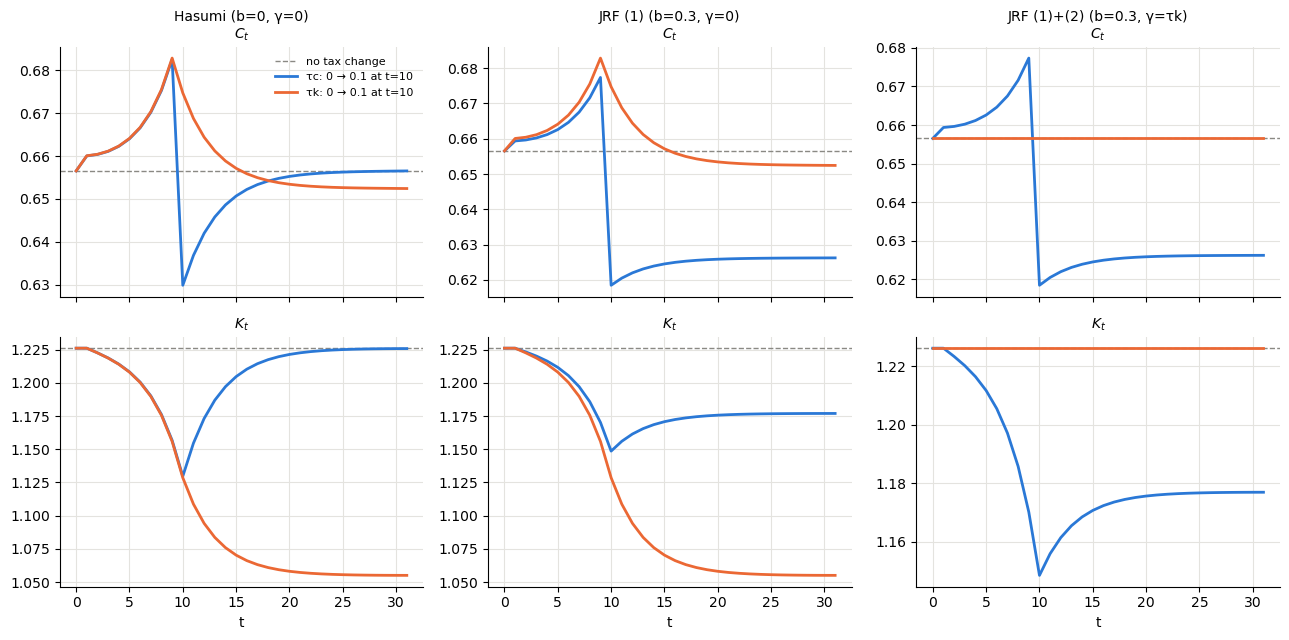

model                          policy       C*       K*  welfare CE (%)
Hasumi (b=0, γ=0)              tc       0.6565   1.2259          -0.006
Hasumi (b=0, γ=0)              tk       0.6524   1.0550          -0.322
JRF (1) (b=0.3, γ=0)           tc       0.6263   1.1770          -4.119
JRF (1) (b=0.3, γ=0)           tk       0.6524   1.0550          -0.322
JRF (1)+(2) (b=0.3, γ=τk)      tc       0.6263   1.1770          -4.119
JRF (1)+(2) (b=0.3, γ=τk)      tk       0.6565   1.2261           0.000


In [12]:
T = 30
cases = [("Hasumi (b=0, γ=0)", 0.0, False),
         ("JRF (1) (b=0.3, γ=0)", 0.3, False),
         ("JRF (1)+(2) (b=0.3, γ=τk)", 0.3, True)]
paths = {}
for name, b, gflag in cases:
    for pol in ["none", "tc", "tk"]:
        tc = np.zeros(T + 2); tk = np.zeros(T + 2)
        if pol == "tc": tc[10:] = 0.1
        if pol == "tk": tk[10:] = 0.1
        gam = tk.copy() if gflag else np.zeros(T + 2)
        paths[name, pol] = transition(tc, tk, gam, b, T)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True)
tt = np.arange(T + 2)
for j, (name, b, gflag) in enumerate(cases):
    for i, var in enumerate(["C", "K"]):
        ax = axes[i, j]
        base = paths[name, "none"][i]
        ax.axhline(base[0], color="#8a8984", lw=1, ls="--", label="no tax change")
        ax.plot(tt, paths[name, "tc"][i], color=COL[0], label="τc: 0 → 0.1 at t=10")
        ax.plot(tt, paths[name, "tk"][i], color=COL[1], label="τk: 0 → 0.1 at t=10")
        ax.set_title(f"{name}\n${var}_t$" if i == 0 else f"${var}_t$", fontsize=10)
        if i == 1: ax.set_xlabel("t")
axes[0, 0].legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()

print(f"{'model':30s} {'policy':6s} {'C*':>8s} {'K*':>8s} {'welfare CE (%)':>15s}")
for name, b, gflag in cases:
    W0 = welfare(paths[name, "none"][0])
    for pol in ["tc", "tk"]:
        C, K = paths[name, pol]
        print(f"{name:30s} {pol:6s} {C[-1]:8.4f} {K[-1]:8.4f} {ce(welfare(C), W0):15.3f}")

蓮見モデル(左列)では、$\tau_c$ の引き上げは「駆け込み」の一時的な変動を生むだけで、定常状態は変わらない。
一方、$\tau_k$ は $K^{\ast}$ と $C^{\ast}$ を下げる。これが本の結論である。

(表の $K^{\ast}$ は $T+1=31$ 期の値。R ソースと同じく $C_{T+1}$ だけを定常値に固定しているため、定常値と小数第 4 位で差が出ることがある。)

JRF (1)(中列)では、消費税も $K^{\ast}, C^{\ast}$ を下げる。$b=0.3$ では、その影響は資本課税より大きい。
JRF (1)+(2)(右列)では、資本課税は経路に何の影響も与えず、消費税だけが厚生を下げる。**結論が逆転する。**

ただし、この比較は税収が同じではない($\tau_c = 0.1$ と $\tau_k = 0.1$ では税収が違う)。
そこで次に、税収を中立にして最適な組合せを求める。

### 6.2 税収中立な最適税率の組合せ

定常状態の税収 $R = \tau_c C^{\ast} + \tau_k r^{\ast} K^{\ast}$ を一定($R = 0.05$、GDP の約 5%)に保つ。
各 $\tau_k$ に対し、これを満たす $\tau_c$ を求める。
$t=1$ から恒久的に税制を変えた場合の生涯厚生を、$\tau_k$ の関数として描き、最大化する。
ここでは $\gamma = 0$ とする($\gamma=\tau_k$ だと資本税収は還元されて財源にならない)。
図には $b \le 0.1$ だけを描く($b = 0.3$ は厚生の変化が一桁大きいので表のみ示す)。

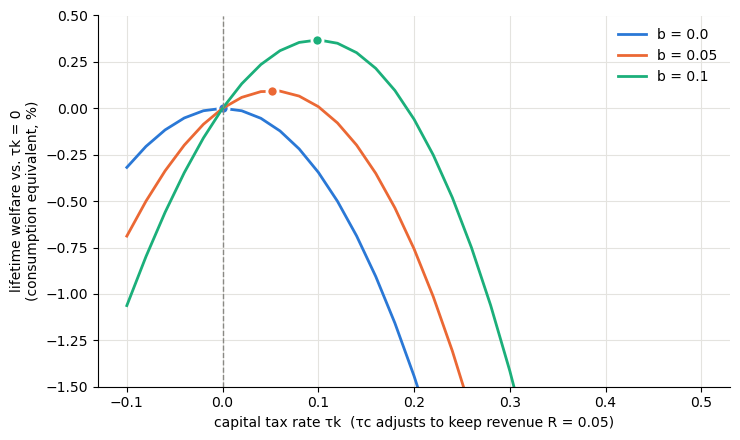

    b      τk*      τc*   gain vs τk=0 (%CE)
 0.00  -0.0000   0.0762              -0.0000
 0.05   0.0518   0.0520               0.0950
 0.10   0.0987   0.0308               0.3687
 0.30   0.2486  -0.0327               3.0062


In [13]:
T_long = 150
R = 0.05

def ss_revenue(tc, tk, b):
    C, K = steady(tk, tc, 0.0, b)
    Ae = A / (1 + tc) ** b
    return tc * C + tk * alpha * Ae * K ** alpha

def tc_for(tk, b):
    return scipy.optimize.brentq(lambda x: ss_revenue(x, tk, b) - R, -0.5, 3.0)

def lifetime(tk, b):
    tc0 = tc_for(tk, b)
    tc = np.full(T_long + 2, tc0); tk_ = np.full(T_long + 2, tk)
    tc[0] = 0.0; tk_[0] = 0.0          # t=0 は税のない旧定常状態
    C, K = transition(tc, tk_, np.zeros(T_long + 2), b, T_long)
    return welfare(C), tc0

bs = [0.0, 0.05, 0.1, 0.3]
grid = np.linspace(-0.1, 0.5, 31)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
rows = []
for k, b in enumerate(bs):
    W_ref, _ = lifetime(0.0, b)
    ws = np.array([lifetime(x, b)[0] for x in grid])
    i = int(np.argmax(ws))
    res = scipy.optimize.minimize_scalar(lambda x: -lifetime(x, b)[0],
                                         bounds=(grid[max(i - 1, 0)], grid[min(i + 1, len(grid) - 1)]),
                                         method="bounded")
    Wopt, tcopt = lifetime(res.x, b)
    rows.append((b, res.x, tcopt, ce(Wopt, W_ref)))
    if b > 0.1:
        continue  # b=0.3 は縦軸のスケールが大きく違うので表のみ
    ax.plot(grid, ce(ws, W_ref), color=COL[k], label=f"b = {b}")
    ax.plot([res.x], [ce(Wopt, W_ref)], "o", color=COL[k], ms=8, mec="white", mew=2)
ax.axvline(0, color="#8a8984", lw=1, ls="--")
ax.set_xlabel("capital tax rate τk  (τc adjusts to keep revenue R = 0.05)")
ax.set_ylabel("lifetime welfare vs. τk = 0\n(consumption equivalent, %)")
ax.set_ylim(-1.5, 0.5)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(f"{'b':>5s} {'τk*':>8s} {'τc*':>8s} {'gain vs τk=0 (%CE)':>20s}")
for b, tk_opt, tc_opt, gain in rows:
    print(f"{b:5.2f} {tk_opt:8.4f} {tc_opt:8.4f} {gain:20.4f}")

* $b=0$(蓮見モデル)では、生涯厚生を最大にする資本税率は $\tau_k^{\ast} \approx 0$ である。
  税収は消費税ですべて賄うのが最適で、Chamley–Judd の結論が数値的にも再現される。
* $b>0$ では $\tau_k^{\ast} > 0$ となり、資本課税と消費税を組み合わせるのが最適になる。
  興味深いことに、この較正では $b$ が小さいとき $\tau_k^{\ast} \approx b$ となっている。
* $b = 0.3$ では $\tau_c^{\ast} < 0$(消費補助)まで行く。
  これは (1) の定式化が、消費税と実効生産性を対称に結び付けているためである。
  JRF の (1) にも単純化された恣意性があることを示している。
  それでも「$\tau_k=0$ はモデルの付け方次第で最適でなくなる」という本稿の論点は変わらない。

### 6.3 楔定理の数値確認

Lean の `optimal_capital_tax` が示すように、$\tau_k^\dagger = 1 + \gamma - (1+\tau_c)^b$ と置けば、
$(\tau_c, \gamma, b)$ が何であれ、定常資本はラムゼイ・モデルの修正黄金律 $K_R$ に一致するはずである。

In [14]:
_, K_R = steady(0.0, 0.0, 0.0, 0.0)
print(f"Ramsey (2.28) modified golden rule: K_R = {K_R:.6f}")
for tc, gam, b in [(0.1, 0.0, 0.0), (0.1, 0.0, -0.3), (0.2, 0.0, -0.3), (0.1, 0.0, 0.3),
                   (0.1, 0.05, 0.3), (0.2, 0.1, 0.3), (0.1, 0.1, 1.0)]:
    tk_dag = 1 + gam - (1 + tc) ** b
    _, K = steady(tk_dag, tc, gam, b)
    print(f"τc={tc:4.2f} γ={gam:4.2f} b={b:3.1f}  ->  τk† = {tk_dag:+.4f},  K* = {K:.6f}")

Ramsey (2.28) modified golden rule: K_R = 1.226145
τc=0.10 γ=0.00 b=0.0  ->  τk† = +0.0000,  K* = 1.226145
τc=0.10 γ=0.00 b=-0.3  ->  τk† = +0.0282,  K* = 1.226145
τc=0.20 γ=0.00 b=-0.3  ->  τk† = +0.0532,  K* = 1.226145
τc=0.10 γ=0.00 b=0.3  ->  τk† = -0.0290,  K* = 1.226145
τc=0.10 γ=0.05 b=0.3  ->  τk† = +0.0210,  K* = 1.226145
τc=0.20 γ=0.10 b=0.3  ->  τk† = +0.0438,  K* = 1.226145
τc=0.10 γ=0.10 b=1.0  ->  τk† = +0.0000,  K* = 1.226145


## 7. 結論

1. 蓮見モデル(Chamley–Judd 型の財政モデル)では、資本課税ゼロ・消費税で賄うのが最適である。これは Lean で証明でき(§1–§2)、生涯厚生の数値計算でも再現できる(6.2 節, $b=0$)。
   ただしその理由は、非弾力的な労働供給のもとで一定の消費税が**一括税**になるからにすぎない。
2. JRF の変形を入れるとこの結論は崩れる。(1) 消費税が資本財や既存資本にも掛かること、(2) 公共投資が資本の持ち主に戻ること、の二つである。
   ラムゼイ配分を再現する資本税率は $\tau_k^\dagger = 1+\gamma-(1+\tau_c)^b$ となり、消費税と公共投資に連動して決まる。
   JRF 2025 の読み($b<0$)では、これは正で、$\tau_c$ とともに増える。消費税を上げるなら資本課税も上げるべきである。
   $\gamma=\tau_k$ では結論が逆転し、消費税の引き上げが厚生を悪化させる(§3、Lean)。
   税収中立の数値実験でも、$b>0$ なら最適な資本税率は正になる(6.2 節)。
3. 予算制約 (3.2) に政府支出 $g_t$ を足し戻すと、税は恒等的に消え、ラムゼイ・モデル (2.28) に戻る(§4、Lean)。
   Chamley–Judd の長期目標そのものが、このラムゼイ・モデルの修正黄金律である。
4. したがって、Chamley–Judd の結論の本体は「**長期的には楔を消せ**」であり、「**資本税をゼロにせよ**」ではない。
   どの税が楔を生むかは、税と還元を家計がどう認識するかという帳簿の付け方で決まり、真の世界(ラムゼイ・モデル)からは決まらない。
   JRF の (2) が恣意的なら、蓮見モデルの (3.2) も同じ程度に恣意的である。
   「資本課税ゼロが望ましい」という主張は、その恣意的な選択に依存した結論にすぎない。
5. JRF の当初の問題意識は、AI という資本の蓄積を最優先すれば人間の消費の余地が削られる、というものだった。
   本稿の結果は、少なくとも「効率性の理論が資本課税ゼロを要求する」という反論は、その問題意識を退ける根拠にならないことを示している。
   自動化資本への課税は、最適課税論の主流でもすでに論じられている(Guerreiro–Rebelo–Teles 2022; Costinot–Werning 2023)。

**限界と今後の課題**(Claude による注記):

* 本稿の Lean 証明は、定常状態と、予算制約 (3.2) からの二期間の変分によるオイラー方程式の導出までである。無限期間の和 (3.1) や、移行過程を含む最適課税問題(ラムゼイ問題)そのものは形式化しておらず、生涯厚生については数値計算に頼った。
* 労働供給を内生化すると消費税は労働を歪める。その場合の比較(Atkinson–Stiglitz, Chamley の原モデル)は扱っていない。
* (1) の $b$ や (2) の $\gamma$ の大きさは実証的に詰めていない。日本の住宅投資や控除対象外消費税の規模から $b'$ を推定するのは自然な次の一歩である。
* 文献上も、異質な家計・不完備市場(Aiyagari 1995)、ライフサイクル(Conesa–Kitao–Krueger 2009)、
  効用の形状(Lansing 1999; Straub–Werning 2020)によって、長期の最適資本課税は正になりうることが知られている。
  本稿の議論は、代表的家計という Chamley–Judd の土俵の中でも「ゼロ」が頑健でないことを示した点に位置付けられる。

## 付録: Lean による一括検証

ここまでの `%%writefile` セルで `CJ_formula.lean` が出来上がっている。以下で Lean 4 (v4.34.1) + Mathlib (v4.34.1) をそろえ、まとめて検証する。

* **Colab**:elan をインストールし、`cjlean/` に Mathlib を依存に持つ Lake プロジェクトを作る。
  `lake exe cache get` でビルド済みの .olean を取得する(初回は数分)。
* **ローカル**:カレントディレクトリにすでに Mathlib 入りの `lakefile.lean` があれば、それをそのまま使う。

本稿のファイルは Mathlib だけに依存し、1 回検証すれば済む。
そのため、`--incr-header-save` / `--incr-load` によるスナップショットは使わず、`lake env lean` を 1 回走らせる。
途中で何度も検証したい場合は、ヘッダ(`import Mathlib`)のスナップショットを保存すると 2 回目以降が速くなる。

In [15]:
%%bash
set -e
export PATH="$HOME/.elan/bin:$PATH"
if [ -f lakefile.lean ] && grep -q mathlib lakefile.lean; then
  echo "using the existing Lake project in the current directory"
  echo "." > .leandir
else
  if ! command -v lake >/dev/null 2>&1; then
    curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh \
      | sh -s -- -y --default-toolchain none
  fi
  mkdir -p cjlean && cd cjlean
  echo 'leanprover/lean4:v4.34.1' > lean-toolchain
  cat > lakefile.lean <<'EOF'
import Lake
open Lake DSL

package cjlean

require mathlib from git
  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"
EOF
  lake update 2>&1 | tail -3
  lake exe cache get 2>&1 | tail -3
  cd ..
  echo "cjlean" > .leandir
fi

using the existing Lake project in the current directory


In [16]:
%%bash
export PATH="$HOME/.elan/bin:$PATH"
LEANDIR=$(cat .leandir)
FILE=$(pwd)/CJ_formula.lean
cd "$LEANDIR"
time lake env lean "$FILE" && echo "=== CJ_formula.lean: all theorems checked ==="

'CJ.Params.cj_core' depends on axioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.euler_from

_budget' depends on axioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.ramsey_euler_from_bud

get' depends on axioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.hasumi_capital_tax_harmfu

l' depends on axioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.jrf_reversal' depends on ax

ioms: [propext, Classical.choice, Quot.sound]
'CJ.Params.optimal_capital_tax' depends on axioms: [pr

opext, Classical.choice, Quot.sound]
'CJ.Params.back_to_ramsey' depends on axioms: [propext, Classic

al.choice, Quot.sound]



real	0m22.969s
user	0m4.766s
sys	0m3.784s


=== CJ_formula.lean: all theorems checked ===
